# K6: TF-IDF, logistička regresija naspram stabla odlučivanja (online prodavnica odeće)
**Tip:** Blok 2, zadatak 2. Reprezentacija: TF-IDF. Dva klasifikatora koja se porede, pa podešavanje stabla.

### Zadatak
U fajlu `E-Commerce_Reviews_for_class.csv` su komentari kupaca online prodavnice odeće (`Clothing ID`, `Age`, `Title`, `Review Text`, `Rating`).
- Napraviti kolonu `review_content` spajanjem `Title` i `Review Text`.
- Od kolone `Rating` napraviti `sentiment` (1 i 2 negativan, 3 neutralan, 4 i 5 pozitivan).
- Transformisati `review_content` primenom **TF-IDF**. Proceniti da li još neku varijablu treba uključiti.
- Prvi model: **logistička regresija**, podrazumevani hiperparametri. Drugi model: **stablo odlučivanja**, podrazumevani hiperparametri. Uporediti ih.
- Treći model: **podešeno stablo** (jedan hiperparametar za TF-IDF, jedan za stablo, 5-fold kros-validacija), uz komentar šta bi sve podešavao.
- Uporediti sva tri modela i `DummyClassifier` kao donju granicu.

In [3]:
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import RobustScaler, OneHotEncoder, MinMaxScaler, FunctionTransformer
from sklearn import metrics
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, balanced_accuracy_score
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline   # imblearn Pipeline radi i bez SMOTE-a, pa moze da ostane uvek

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier

import matplotlib.pyplot as plt
import seaborn as sb

from pathlib import Path
from IPython.display import display

import spacy

RAND_STATE = 1
DATA_DIR = Path.cwd().parent / 'data'

### Šta je urađeno
- Učitani podaci, napravljena `review_content` (prazan naslov se menja praznim stringom da ne "pokvari" spoj).
- Napravljena izlazna varijabla `sentiment` (pozitivnih je najviše).
- Pregledani `Age` (kdeplot) i `Clothing ID` (broj vrednosti).
- Odluka: ulaz je samo `review_content`.
- Podela 80:20 sa `stratify`.

In [4]:
data = pd.read_csv(DATA_DIR / 'E-Commerce_Reviews_for_class.csv')
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Clothing ID  3000 non-null   int64
 1   Age          3000 non-null   int64
 2   Title        3000 non-null   str  
 3   Review Text  3000 non-null   str  
 4   Rating       3000 non-null   int64
dtypes: int64(3), str(2)
memory usage: 117.3 KB


In [5]:
data['Title'] = data['Title'].fillna('')
data = data.dropna(subset=['Review Text']).reset_index(drop=True)
data['review_content'] = data['Title'] + '. ' + data['Review Text']
print(data['review_content'].head(3).tolist())

['More beautiful in person. I bought this in the store and love it. seeing it online - i would never think to buy it. much more flattering in person!', 'Wonderful. This wide leg pant gives the perception of a skirt that is feminine, comfortable, and moves beautifully when you walk. can be used all year round!', 'Not for me. I ordered this with another sweater to compare the two, hoping that one would be what i was looking for. the stitching on this sweater is beautiful so i honestly expected to keep this one. i was looking for a cardigan that was on the longer side as i wear leggings often. this cardigan was not as long as it seems in the picture (hit at my hips, 5\'10" tall). the material seems stiff and a bit rough. the sizing is a bit boxy because it is wide/big cardigan but also short. the stitching was just as']


In [6]:
def rating_to_sentiment(rating: int):
    if rating < 3:
        return 'negativan'
    return 'neutralan' if rating == 3 else 'pozitivan'

data['sentiment'] = data['Rating'].apply(rating_to_sentiment)
print(data['sentiment'].value_counts(normalize=True))

sentiment
pozitivan    0.775667
neutralan    0.115000
negativan    0.109333
Name: proportion, dtype: float64


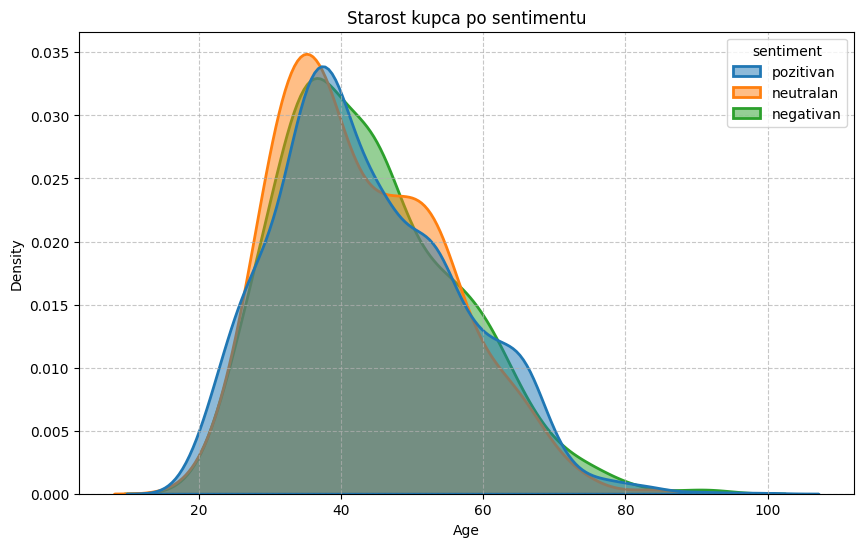

Broj razlicitih proizvoda: 473


In [7]:
plt.figure(figsize=(10, 6))
sb.kdeplot(data=data, x='Age', hue='sentiment',
           fill=True, common_norm=False, alpha=0.5, linewidth=2)
plt.title('Starost kupca po sentimentu')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

print('Broj razlicitih proizvoda:', data['Clothing ID'].nunique())

In [8]:
X = data['review_content']
y = data['sentiment']
y_encodings, y_levels = pd.factorize(y)
print(list(y_levels))

X_train, X_test, y_train, y_test = train_test_split(X, y_encodings,
                                                    test_size=0.2,
                                                    random_state=RAND_STATE,
                                                    stratify=y_encodings)
print(X_train.shape, X_test.shape)

['pozitivan', 'neutralan', 'negativan']
(2400,) (600,)


In [9]:
#logisticka , stablo uporediti , gridseaerch , dummy

In [10]:
nlp_pipe=spacy.load('en_core_web_sm')

In [11]:
def spacy_sredi_tekst(doc):
    tokens=nlp_pipe(doc)
    ocisceniTokeni=[]
    for token in tokens:
        lemma_lower=token.lemma_.lower()
        if lemma_lower in ['not','no']:
            ocisceniTokeni.append(lemma_lower)
            continue
        if token.is_stop or token.is_punct or token.like_url or token.is_space or token.like_email or token.like_url:
            continue
        ocisceniTokeni.append(lemma_lower)
    return ocisceniTokeni


In [12]:
vectorizer=TfidfVectorizer(
        tokenizer=spacy_sredi_tekst,
        analyzer="word",
        stop_words=None,
        token_pattern=None,
        ngram_range=(1, 2),
        max_df=0.95,
        min_df=0.01,
        max_features=None)

In [13]:
logisticka=LogisticRegression(class_weight='balanced',max_iter=1500,C=1,random_state=42)

In [17]:
stablo=DecisionTreeClassifier(random_state=42,class_weight='balanced')

In [ ]:
# #kako imamo mnogo ne balansiran data set koristimo smote
# pozitivan    0.775667
# neutralan    0.115000
# negativan    0.109333

In [21]:
pipe_log=Pipeline([
    ('vectorizer',vectorizer),
    ('smote',SMOTE(random_state=42)),
    ('cls_log',logisticka)
])

In [22]:
pipe_stablo=Pipeline([
    ('vectorizer',vectorizer),
    ('smote',SMOTE(random_state=42)),
    ('cls_stablo',stablo)
])

In [23]:
model_log=pipe_log.fit(X_train,y_train)

In [24]:
model_stablo=pipe_stablo.fit(X_train,y_train)

In [42]:
dummy_clf = DummyClassifier(strategy="most_frequent")
dummy_clf.fit(X_train, y_train)

,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'most_frequent'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",None
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None


In [28]:
predict_dummy=dummy_clf.predict(X_test)

In [30]:
predict_stablo=pipe_stablo.predict(X_test)

In [31]:
predict_log=pipe_log.predict(X_test)

In [33]:
params={
    'cls_stablo__max_depth':[10,25,50],
    'vectorizer__min_df':[0.05,1,3]
}

In [34]:
cv=GridSearchCV(pipe_stablo,param_grid=params,scoring='f1_macro',cv=5,verbose=2)

In [36]:
cv=cv.fit(X_train,y_train)

Fitting 5 folds for each of 9 candidates, totalling 45 fits
[CV] END ..cls_stablo__max_depth=10, vectorizer__min_df=0.05; total time=  23.8s
[CV] END ..cls_stablo__max_depth=10, vectorizer__min_df=0.05; total time=  26.2s
[CV] END ..cls_stablo__max_depth=10, vectorizer__min_df=0.05; total time=  19.9s
[CV] END ..cls_stablo__max_depth=10, vectorizer__min_df=0.05; total time=  33.1s
[CV] END ..cls_stablo__max_depth=10, vectorizer__min_df=0.05; total time=  39.0s
[CV] END .....cls_stablo__max_depth=10, vectorizer__min_df=1; total time=  24.9s
[CV] END .....cls_stablo__max_depth=10, vectorizer__min_df=1; total time=  20.5s
[CV] END .....cls_stablo__max_depth=10, vectorizer__min_df=1; total time=  21.2s
[CV] END .....cls_stablo__max_depth=10, vectorizer__min_df=1; total time=  26.8s
[CV] END .....cls_stablo__max_depth=10, vectorizer__min_df=1; total time=  30.6s
[CV] END .....cls_stablo__max_depth=10, vectorizer__min_df=3; total time=  43.8s
[CV] END .....cls_stablo__max_depth=10, vectorize

In [37]:
def get_model_metrics(y_true:np.ndarray, y_pred:np.ndarray, model_name:str):

    # compute P, R, F1 for both averages
    report = classification_report(y_true, y_pred, output_dict=True)

    # compute balanced accuracy
    b_acc = balanced_accuracy_score(y_true, y_pred)

    # extract metrics for the specified averages
    macro_avg = report['macro avg']
    weighted_avg = report['weighted avg']

    results = {
        'Model': model_name,
        'Macro Precision': macro_avg['precision'],
        'Macro Recall': macro_avg['recall'],
        'Macro F1-Score': macro_avg['f1-score'],
        'Weighted Precision': weighted_avg['precision'],
        'Weighted Recall': weighted_avg['recall'],
        'Weighted F1-Score': weighted_avg['f1-score'],
        'Balanced Accuracy': b_acc
    }

    return results

In [38]:
cv_model=cv.best_estimator_

In [39]:
predict_cv=cv_model.predict(X_test)

In [40]:
pd.DataFrame([get_model_metrics(y_test,predict_dummy,"DUMMY"),get_model_metrics(y_test,predict_log,"LOG MODEL"),get_model_metrics(y_test,predict_stablo,"STABLO 1"),get_model_metrics(y_test,predict_cv,"STABLO IZ CV")]).round(2)

C:\Users\Tea\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Tea\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Tea\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, 

,Model,Macro Precision,Macro Recall,Macro F1-Score,Weighted Precision,Weighted Recall,Weighted F1-Score,Balanced Accuracy
0,DUMMY,0.26,0.33,0.29,0.60,0.78,0.68,0.33
1,LOG MODEL,0.54,0.59,0.55,0.80,0.74,0.77,0.59
2,STABLO 1,0.45,0.47,0.45,0.73,0.68,0.70,0.47
3,STABLO IZ CV,0.45,0.45,0.45,0.71,0.70,0.71,0.45
